In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dtime = pd.read_csv("delivery_time.csv")
dtime

,DeliveryTime,SortingTime
0,21.00,10
1,13.50,4
2,19.75,6
3,24.00,9
4,29.00,10
5,15.35,6
6,19.00,7
7,9.50,3
8,17.90,10
9,18.75,9


In [3]:
dtime.shape

(21, 2)

In [4]:
dtime.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   DeliveryTime  21 non-null     float64
 1   SortingTime   21 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 464.0 bytes


In [5]:
dtime.isnull().sum()

DeliveryTime    0
SortingTime     0
dtype: int64

In [6]:
dtime.describe()

,DeliveryTime,SortingTime
count,21.000000,21.000000
mean,16.790952,6.190476
std,5.074901,2.542028
min,8.000000,2.000000
25%,13.500000,4.000000
50%,17.830000,6.000000
75%,19.750000,8.000000
max,29.000000,10.000000


In [7]:
dtime.columns

Index(['DeliveryTime', 'SortingTime'], dtype='object')

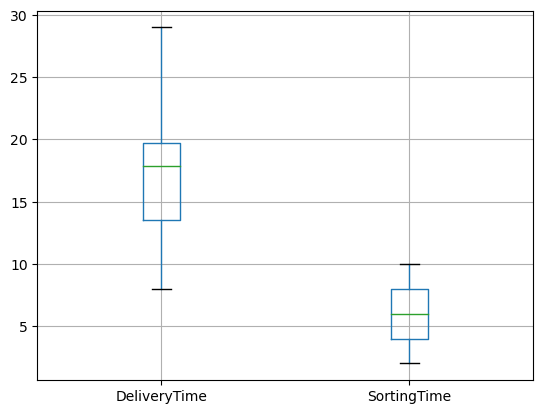

In [8]:
dtime.boxplot()
plt.show()

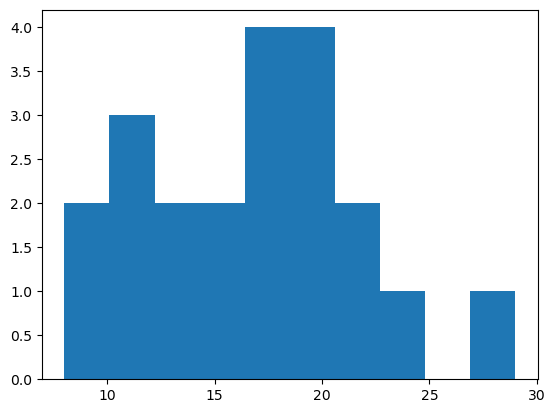

In [9]:
plt.hist(dtime['DeliveryTime'])
plt.show()

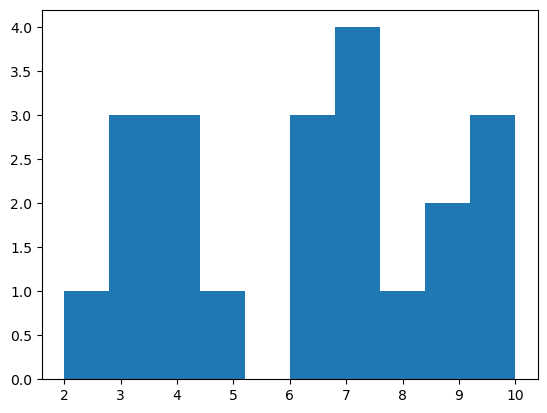

In [10]:
plt.hist(dtime['SortingTime'])
plt.show()

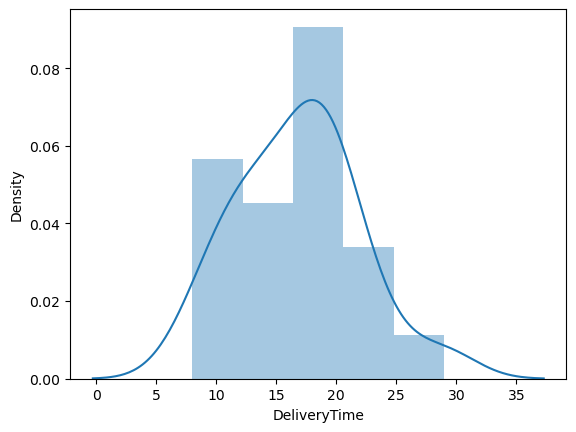

In [11]:
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.distplot(dtime['DeliveryTime'])
plt.show()

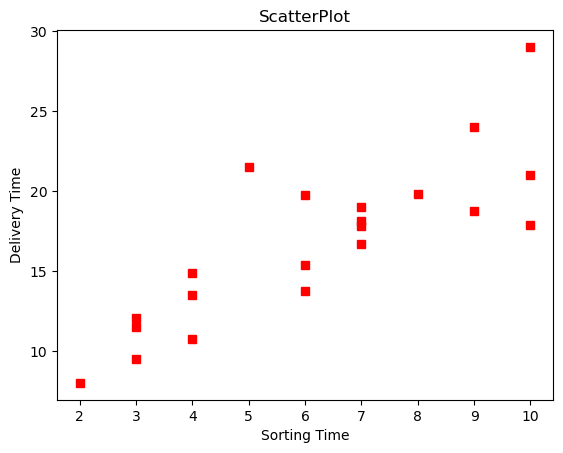

In [12]:
plt.plot(dtime['SortingTime'],dtime['DeliveryTime'],"rs")
plt.xlabel("Sorting Time")
plt.ylabel("Delivery Time")
plt.title("ScatterPlot") 
plt.show()

In [13]:
# Here in above Scatter plot we can clearly see positive coreletion between DT and ST

In [14]:
dtime.corr()

,DeliveryTime,SortingTime
DeliveryTime,1.000000,0.825997
SortingTime,0.825997,1.000000


In [15]:
# As r > 0.8 we can say that there is strong positive corelation between Delivery and Sorting Time

In [16]:
# Set Target = 75%
import statsmodels.formula.api as smf
# Linear Model
model1 = smf.ols('DeliveryTime~SortingTime',data=dtime).fit()
model1.params

Intercept      6.582734
SortingTime    1.649020
dtype: float64

In [17]:
# Linear Regression Equation here can be written as - DeliveryTime = 6.5827 + 1.6490(SortingTime)
# p value = 0.000 which is less than 0.05 - thus ST is a significant variable 
# R**2 value here = 0.682 = 68.2% 

In [18]:
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           DeliveryTime   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.666
Method:                 Least Squares   F-statistic:                     40.80
Date:                Tue, 09 Jan 2024   Prob (F-statistic):           3.98e-06
Time:                        18:48:25   Log-Likelihood:                -51.357
No. Observations:                  21   AIC:                             106.7
Df Residuals:                      19   BIC:                             108.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       6.5827      1.722      3.823      0.001       2.979      10.186
SortingTime     1.6490      0.258      6.387      0.000       1.109       2.189
==============================================================================
Omnibus:                        3.649   Durbin-Watson:                   1.248
Prob(Omnibus):                  0.161   Jarque-Bera (JB):                2.086
Skew:                           0.750   Prob(JB):                        0.352
Kurtosis:                       3.367   Cond. No.                         18.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:
pred1 = model1.predict(dtime.SortingTime)
np.round(pred1,2)

0     23.07
1     13.18
2     16.48
3     21.42
4     23.07
5     16.48
6     18.13
7     11.53
8     23.07
9     21.42
10    19.77
11    13.18
12    18.13
13    11.53
14    11.53
15    13.18
16    16.48
17    18.13
18     9.88
19    18.13
20    14.83
dtype: float64

In [20]:
model1.resid

0    -2.072933
1     0.321186
2     3.273147
3     2.576087
4     5.927067
5    -1.126853
6     0.874127
7    -2.029794
8    -5.172933
9    -2.673913
10    0.055107
11   -2.428814
12   -1.445873
13   -0.029794
14    0.500206
15    1.701186
16   -2.726853
17   -0.015873
18   -1.880774
19   -0.295873
20    6.672167
dtype: float64

In [21]:
rmse_lin = np.sqrt(np.mean((np.array(dtime.DeliveryTime)-np.array(pred1))**2))
rmse_lin

2.7916503270617654

In [22]:
# Next Actual values vs Predicted values Scatter Plot

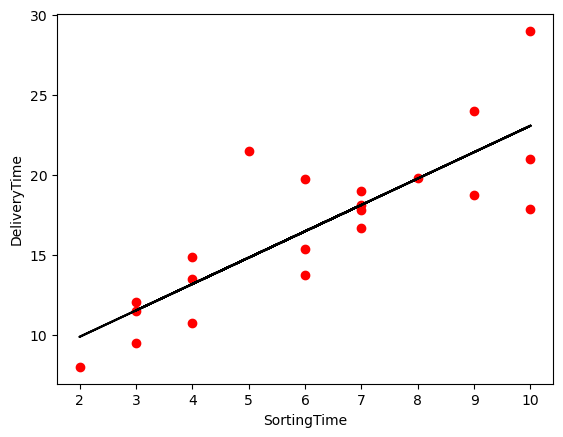

In [23]:
plt.scatter(x=dtime.SortingTime,y=dtime.DeliveryTime,color='red')
plt.plot(dtime.SortingTime,pred1,color='black')
plt.xlabel("SortingTime")
plt.ylabel("DeliveryTime")
plt.show()

In [24]:
# Log Model
model2=smf.ols('DeliveryTime~np.log(SortingTime)',data=dtime).fit()

In [25]:
model2.params

Intercept              1.159684
np.log(SortingTime)    9.043413
dtype: float64

In [26]:
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           DeliveryTime   R-squared:                       0.695
Model:                            OLS   Adj. R-squared:                  0.679
Method:                 Least Squares   F-statistic:                     43.39
Date:                Tue, 09 Jan 2024   Prob (F-statistic):           2.64e-06
Time:                        18:48:26   Log-Likelihood:                -50.912
No. Observations:                  21   AIC:                             105.8
Df Residuals:                      19   BIC:                             107.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               1.1597      2.455      0.472      0.642      -3.978       6.297
np.log(SortingTime)     9.0434      1.373      6.587      0.000       6.170      11.917
==============================================================================
Omnibus:                        5.552   Durbin-Watson:                   1.427
Prob(Omnibus):                  0.062   Jarque-Bera (JB):                3.481
Skew:                           0.946   Prob(JB):                        0.175
Kurtosis:                       3.628   Cond. No.                         9.08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
pred2 = model2.predict(pd.DataFrame(dtime.SortingTime))
pred2

0     21.982913
1     13.696517
2     17.363305
3     21.030094
4     21.982913
5     17.363305
6     18.757354
7     11.094889
8     21.982913
9     21.030094
10    19.964933
11    13.696517
12    18.757354
13    11.094889
14    11.094889
15    13.696517
16    17.363305
17    18.757354
18     7.428100
19    18.757354
20    15.714496
dtype: float64

In [28]:
rmse_log=np.sqrt(np.mean((np.array(dtime.DeliveryTime)-np.array(pred2))**2))
rmse_log

2.733171476682066

In [29]:
pred2.corr(dtime.DeliveryTime)

0.8339325279256244

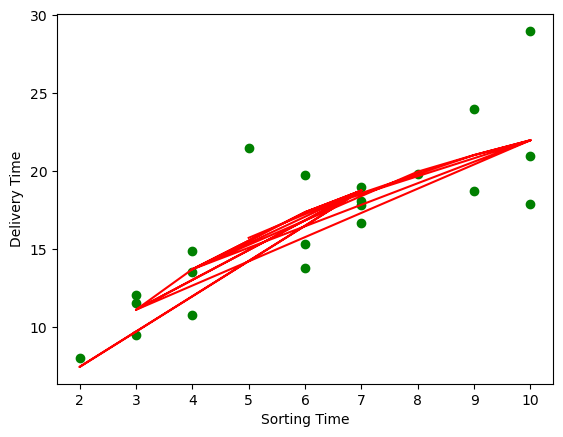

In [30]:
plt.scatter(x=dtime.SortingTime,y=dtime.DeliveryTime,color="green")
plt.plot(dtime.SortingTime,pred2,color="red")
plt.xlabel("Sorting Time")
plt.ylabel("Delivery Time")
plt.show()

In [31]:
# Exponential Model
model3 = smf.ols("np.log(DeliveryTime)~SortingTime",data=dtime).fit()
model3.params

Intercept      2.121372
SortingTime    0.105552
dtype: float64

In [32]:
model3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     np.log(DeliveryTime)   R-squared:                       0.711
Model:                              OLS   Adj. R-squared:                  0.696
Method:                   Least Squares   F-statistic:                     46.73
Date:                  Tue, 09 Jan 2024   Prob (F-statistic):           1.59e-06
Time:                          18:48:28   Log-Likelihood:                 7.7920
No. Observations:                    21   AIC:                            -11.58
Df Residuals:                        19   BIC:                            -9.495
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       2.1214      0.103     20.601      0.000       1.906       2.337
SortingTime     0.1056      0.015      6.836      0.000       0.073       0.138
==============================================================================
Omnibus:                        1.238   Durbin-Watson:                   1.325
Prob(Omnibus):                  0.538   Jarque-Bera (JB):                0.544
Skew:                           0.393   Prob(JB):                        0.762
Kurtosis:                       3.067   Cond. No.                         18.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [33]:
pred3_log = model3.predict(pd.DataFrame(dtime.SortingTime))
pred3_log

0     3.176888
1     2.543578
2     2.754681
3     3.071336
4     3.176888
5     2.754681
6     2.860233
7     2.438027
8     3.176888
9     3.071336
10    2.965785
11    2.543578
12    2.860233
13    2.438027
14    2.438027
15    2.543578
16    2.754681
17    2.860233
18    2.332475
19    2.860233
20    2.649130
dtype: float64

In [34]:
pred3 = np.exp(pred3_log)
pred3

0     23.972032
1     12.725123
2     15.716034
3     21.570707
4     23.972032
5     15.716034
6     17.465597
7     11.450423
8     23.972032
9     21.570707
10    19.409927
11    12.725123
12    17.465597
13    11.450423
14    11.450423
15    12.725123
16    15.716034
17    17.465597
18    10.303411
19    17.465597
20    14.141728
dtype: float64

In [35]:
rmse_exp=np.sqrt(np.mean((np.array(dtime.DeliveryTime)-np.array(pred3))**2)) 
rmse_exp

2.940250323056201

In [36]:
pred3.corr(dtime.DeliveryTime)

0.8085780108289262

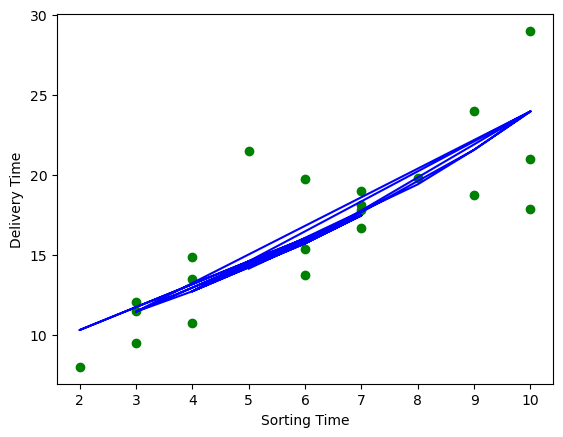

In [37]:
plt.scatter(x=dtime.SortingTime,y=dtime.DeliveryTime,color="green")
plt.plot(dtime.SortingTime,pred3,color="blue")
plt.xlabel("Sorting Time")
plt.ylabel("Delivery Time")
plt.show()

In [38]:
# Combination of Exp + Square model = Quadratic Model

In [39]:
dtime["SortingTime_sq"]=dtime.SortingTime*dtime.SortingTime
dtime

,DeliveryTime,SortingTime,SortingTime_sq
0,21.00,10,100
1,13.50,4,16
2,19.75,6,36
3,24.00,9,81
4,29.00,10,100
5,15.35,6,36
6,19.00,7,49
7,9.50,3,9
8,17.90,10,100
9,18.75,9,81


In [40]:
model_quad=smf.ols("np.log(DeliveryTime)~SortingTime+SortingTime_sq",data=dtime).fit()
model_quad.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     np.log(DeliveryTime)   R-squared:                       0.765
Model:                              OLS   Adj. R-squared:                  0.739
Method:                   Least Squares   F-statistic:                     29.28
Date:                  Tue, 09 Jan 2024   Prob (F-statistic):           2.20e-06
Time:                          18:48:29   Log-Likelihood:                 9.9597
No. Observations:                    21   AIC:                            -13.92
Df Residuals:                        18   BIC:                            -10.79
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          1.6997      0.228      7.441      0.000       1.220       2.180
SortingTime        0.2659      0.080      3.315      0.004       0.097       0.434
SortingTime_sq    -0.0128      0.006     -2.032      0.057      -0.026       0.000
==============================================================================
Omnibus:                        2.548   Durbin-Watson:                   1.369
Prob(Omnibus):                  0.280   Jarque-Bera (JB):                1.777
Skew:                           0.708   Prob(JB):                        0.411
Kurtosis:                       2.846   Cond. No.                         373.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [41]:
pred4_log=model_quad.predict(dtime)
pred4 = np.exp(pred4_log)
pred4

0     21.646921
1     12.909227
2     16.995933
3     21.176938
4     21.646921
5     16.995933
6     18.764526
7     10.825502
8     21.646921
9     21.176938
10    20.191891
11    12.909227
12    18.764526
13    10.825502
14    10.825502
15    12.909227
16    16.995933
17    18.764526
18     8.847949
19    18.764526
20    15.003730
dtype: float64

In [42]:
rmse_quad = np.sqrt(np.mean((np.array(dtime.DeliveryTime)-np.array(pred4))**2)) 
rmse_quad

2.7990419887409246

In [43]:
pred4.corr(dtime.DeliveryTime)

0.825888274991093

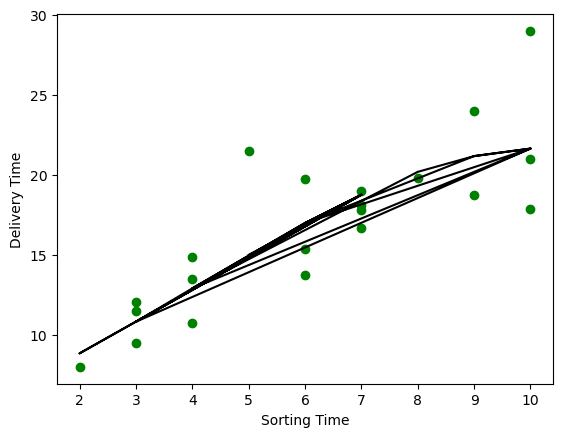

In [44]:
plt.scatter(x=dtime.SortingTime,y=dtime.DeliveryTime,color="green")
plt.plot(dtime.SortingTime,pred4,color="black")
plt.xlabel("Sorting Time")
plt.ylabel("Delivery Time")
plt.show()

In [45]:
data = {"MODEL":pd.Series(["rmse_lin","rmse_log","rmse_exp","rmse_quad"]),
        "RMSE_Values":pd.Series([rmse_lin,rmse_log,rmse_exp,rmse_quad]),
        "Rsquare":pd.Series([model1.rsquared,model2.rsquared,model3.rsquared,model_quad.rsquared])}
table=pd.DataFrame(data)
table 

,MODEL,RMSE_Values,Rsquare
0,rmse_lin,2.791650,0.682271
1,rmse_log,2.733171,0.695443
2,rmse_exp,2.940250,0.710948
3,rmse_quad,2.799042,0.764867


In [46]:
# model_quad is the best model so far with 76.48 % accuracy

In [47]:
print(plt.style.available)   

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'seaborn', 'seaborn-bright', 'seaborn-colorblind', 'seaborn-dark', 'seaborn-dark-palette', 'seaborn-darkgrid', 'seaborn-deep', 'seaborn-muted', 'seaborn-notebook', 'seaborn-paper', 'seaborn-pastel', 'seaborn-poster', 'seaborn-talk', 'seaborn-ticks', 'seaborn-white', 'seaborn-whitegrid', 'tableau-colorblind10']


In [48]:
import matplotlib.pyplot as plt
plt.style.use('classic')

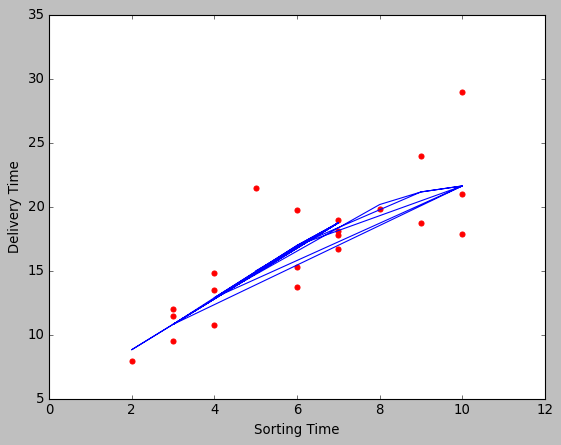

In [53]:
plt.scatter(x=dtime.SortingTime,y=dtime.DeliveryTime,color="red")
plt.plot(dtime.SortingTime,pred4,color="blue")
plt.xlabel("Sorting Time")
plt.ylabel("Delivery Time")
plt.show()

In [50]:
# Thus Delivery Time can be best predicted using model_quad model i.e. exp+sq model